# AurumSignal-ML | Gold Price Movement Classification

Can recent price changes help us predict whether one gram of gold in Turkish lira will rise at the next recorded observation?

We train two models, Logistic Regression and Random Forest, and compare them with a simple rule that always predicts a rise.

## 1. Explore the dataset

In [1]:
import pandas as pd
from IPython.display import display

data_path = "Data/gold_try.csv"
raw_data = pd.read_csv(data_path, encoding="utf-8-sig", dtype=str)

print(f"Dataset: Gold price history in Turkish lira per gram")
print(f"Observations: {len(raw_data):,}")
print(f"Columns in the original CSV: {len(raw_data.columns)}")

preview = raw_data[["Tarih", "Şimdi"]].head().copy()
preview.columns = ["Observation date", "Gold price (TRY per gram)"]
display(preview)

Dataset: Gold price history in Turkish lira per gram
Observations: 1,279
Columns in the original CSV: 7


,Observation date,Gold price (TRY per gram)
0,30.06.2025,"4.198,131"
1,29.06.2025,"4.187,025"
2,27.06.2025,"4.200,042"
3,26.06.2025,"4.254,756"
4,25.06.2025,"4.269,573"


## 2. Prepare dates and prices

Convert the source dates and prices into values Python can compare. Sort the records from oldest to newest so that the next row represents the next observation.

In [2]:
prices = raw_data[["Tarih", "Şimdi"]].copy()
prices.columns = ["date", "price_try"]

prices["date"] = pd.to_datetime(prices["date"], format="%d.%m.%Y")

# The CSV stores 4,198.131 TRY as "4.198,131".
price_text = (
    prices["price_try"]
    .str.strip()
    .str.replace(".", "", regex=False)
    .str.replace(",", ".", regex=False)
)
prices["price_try"] = pd.to_numeric(price_text)

prices = prices.sort_values("date").reset_index(drop=True)

print(f"First observation: {prices['date'].min():%Y-%m-%d}")
print(f"Last observation:  {prices['date'].max():%Y-%m-%d}")
print(f"Missing dates:     {prices['date'].isna().sum()}")
print(f"Missing prices:    {prices['price_try'].isna().sum()}")
print(f"Duplicate dates:   {prices['date'].duplicated().sum()}")

First observation: 2021-01-31
Last observation:  2025-06-30
Missing dates:     0
Missing prices:    0
Duplicate dates:   0


## 3. Define the prediction target

For each observation, compare its price with the next recorded price.

- 1 = the next price rose.
- 0 = the next price fell or stayed flat.

The final observation has no known answer because the dataset ends there.

In [3]:
next_price = prices["price_try"].shift(-1)

prices["rose_next"] = (
    (next_price > prices["price_try"])
    .astype("Int64")
    .where(next_price.notna())
)

target_example = pd.DataFrame({
    "Observation date": prices["date"],
    "Current price (TRY/g)": prices["price_try"],
    "Next price (TRY/g)": next_price,
    "Target": prices["rose_next"],
    "What happened next?": prices["rose_next"].map({
        1: "Price rose",
        0: "Price fell or stayed flat"
    }).fillna("Unknown — last record")
})

print(f"Observations with a known target: {prices['rose_next'].count():,}")
display(target_example.tail(3))

Observations with a known target: 1,278


,Observation date,Current price (TRY/g),Next price (TRY/g),Target,What happened next?
1276,2025-06-27,4200.042,4187.025,0,Price fell or stayed flat
1277,2025-06-29,4187.025,4198.131,1,Price rose
1278,2025-06-30,4198.131,NaN,<NA>,Unknown — last record


## 4. Build the model inputs

At each observation, the model receives three numbers:

1. Price change since the previous record (%).
2. Price change since five records ago (%).
3. Distance from the average price of the latest ten records (%).

All three inputs are available before the next price is observed.

In [4]:
price = prices["price_try"]

prices["return_1_pct"] = price.pct_change(1) * 100
prices["return_5_pct"] = price.pct_change(5) * 100

average_price_10 = price.rolling(window=10).mean()
prices["distance_from_avg_10_pct"] = (price / average_price_10 - 1) * 100

features = [
    "return_1_pct",
    "return_5_pct",
    "distance_from_avg_10_pct"
]

model_data = prices.dropna(subset=features + ["rose_next"]).copy()

print(f"Original observations: {len(prices):,}")
print(f"Ready for modeling:    {len(model_data):,}")

feature_preview = model_data[["date", *features, "rose_next"]].tail(3).copy()
feature_preview.columns = [
    "Date",
    "Change over 1 record (%)",
    "Change over 5 records (%)",
    "Distance from 10-record average (%)",
    "Next price rose (1=yes)"
]
display(feature_preview.round(3))

Original observations: 1,279
Ready for modeling:    1,269


C:\Users\HP\AppData\Local\Temp\ipykernel_18596\1329585757.py:28: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(feature_preview.round(3))


,Date,Change over 1 record (%),Change over 5 records (%),Distance from 10-record average (%),Next price rose (1=yes)
1275,2025-06-26,-0.347,-0.971,-0.670,0
1276,2025-06-27,-1.286,-2.518,-1.710,0
1277,2025-06-29,-0.310,-2.032,-1.746,1


## 5. Split the data by time

Train on older observations and evaluate on newer ones. Leave one record between the two periods because its target depends on the first test price.

In [5]:
split_index = int(len(model_data) * 0.80)

train_data = model_data.iloc[:split_index - 1].copy()
test_data = model_data.iloc[split_index:].copy()

X_train = train_data[features]
y_train = train_data["rose_next"].astype(int)

X_test = test_data[features]
y_test = test_data["rose_next"].astype(int)

split_summary = []

for name, part in [("Training", train_data), ("Testing", test_data)]:
    split_summary.append({
        "Period": name,
        "Records": len(part),
        "First observation": part["date"].iloc[0].date(),
        "Last observation": part["date"].iloc[-1].date()
    })

display(pd.DataFrame(split_summary).set_index("Period"))

,Records,First observation,Last observation
Period,,,
Training,1014,2021-02-10,2024-07-15
Testing,254,2024-07-17,2025-06-29


## 6. Train the classifiers

Logistic Regression combines the three inputs to estimate the probability of a rise. Random Forest combines predictions from 200 decision trees. Both models learn from the same training records.

In [6]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=42)
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=4,
        min_samples_leaf=10,
        random_state=42
    )
}

for model_name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{model_name} trained on {len(X_train):,} observations.")

Logistic Regression trained on 1,014 observations.
Random Forest trained on 1,014 observations.


## 7. Did the models beat the baseline?

The baseline predicts a rise for every observation. We compare both trained models with this rule on the same test dates.

Accuracy counts all correct forecasts. Balanced accuracy gives equal weight to rising and non-rising observations.

In [7]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix

baseline_name = "Always predicts a rise"
predictions = {baseline_name: [1] * len(y_test)}

for model_name, model in models.items():
    predictions[model_name] = model.predict(X_test)

results = []

for method, forecast in predictions.items():
    matrix = confusion_matrix(y_test, forecast, labels=[0, 1])
    correct_non_rises = int(matrix[0, 0])
    correct_rises = int(matrix[1, 1])

    results.append({
        "Method": method,
        "Correct forecasts": correct_non_rises + correct_rises,
        "Accuracy (%)": 100 * accuracy_score(y_test, forecast),
        "Balanced accuracy (%)": 100 * balanced_accuracy_score(y_test, forecast),
        "Correct rises": correct_rises,
        "Correct falls or flat": correct_non_rises
    })

results_table = pd.DataFrame(results).set_index("Method")
display(results_table.round(2))

forest = results_table.loc["Random Forest"]
baseline = results_table.loc[baseline_name]

total_rises = int(y_test.sum())
total_non_rises = len(y_test) - total_rises
gain = int(forest["Correct forecasts"] - baseline["Correct forecasts"])

print(f"Of the {len(y_test)} test observations, {total_rises} rose "
      f"and {total_non_rises} fell or stayed flat.")
print(f"Random Forest identified {int(forest['Correct rises'])} of {total_rises} rises "
      f"and {int(forest['Correct falls or flat'])} of {total_non_rises} falls or flat prices.")
print(f"Compared with always predicting a rise, Random Forest made "
      f"{gain} additional correct forecasts.")

,Correct forecasts,Accuracy (%),Balanced accuracy (%),Correct rises,Correct falls or flat
Method,,,,,
Always predicts a rise,148,58.27,50.00,148,0
Logistic Regression,148,58.27,50.00,148,0
Random Forest,150,59.06,52.28,138,12


Of the 254 test observations, 148 rose and 106 fell or stayed flat.
Random Forest identified 138 of 148 rises and 12 of 106 falls or flat prices.
Compared with always predicting a rise, Random Forest made 2 additional correct forecasts.


## 8. What did the model predict, and what happened next?

Read each row from left to right: the observed price, the Random Forest forecast, the next recorded price, the actual movement, and the result.

The eight rows below illustrate individual decisions. Overall accuracy uses all 254 test observations.

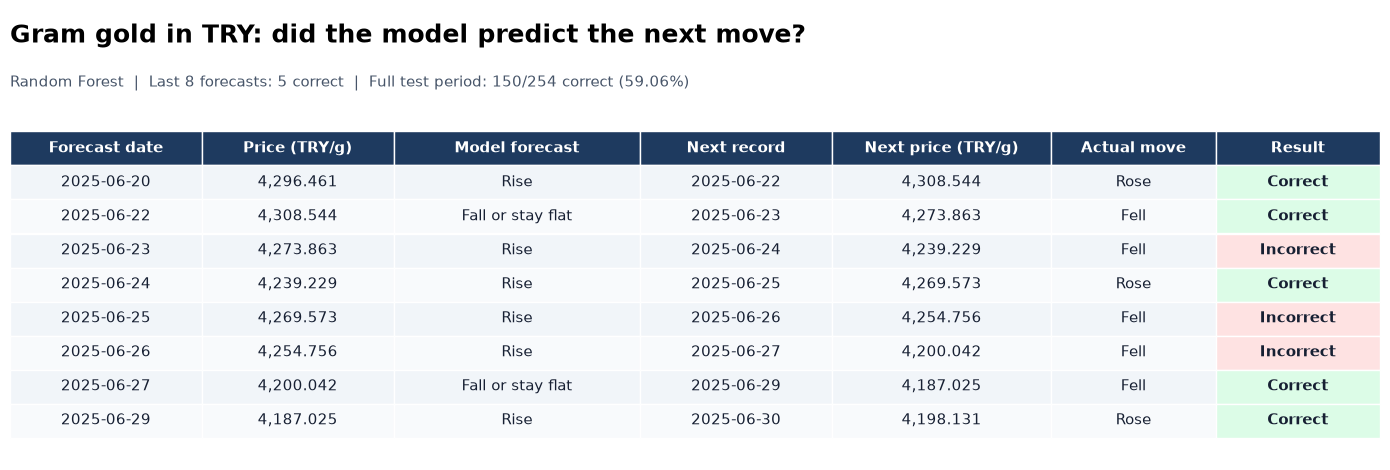

In [8]:
import matplotlib.pyplot as plt

review = test_data[["date", "price_try"]].copy()
review["next_date"] = prices["date"].shift(-1).reindex(review.index)
review["next_price"] = next_price.reindex(review.index)
review["prediction"] = predictions["Random Forest"]
review["correct"] = review["prediction"].eq(y_test)

recent = review.tail(8)
table_rows = []

for row in recent.itertuples():
    if row.next_price > row.price_try:
        actual = "Rose"
    elif row.next_price < row.price_try:
        actual = "Fell"
    else:
        actual = "Stayed flat"

    table_rows.append([
        row.date.strftime("%Y-%m-%d"),
        f"{row.price_try:,.3f}",
        "Rise" if row.prediction == 1 else "Fall or stay flat",
        row.next_date.strftime("%Y-%m-%d"),
        f"{row.next_price:,.3f}",
        actual,
        "Correct" if row.correct else "Incorrect"
    ])

fig, ax = plt.subplots(figsize=(14, 4.8))
ax.axis("off")

ax.text(
    0, 0.97,
    "Gram gold in TRY: did the model predict the next move?",
    transform=ax.transAxes, fontsize=18, weight="bold", va="top"
)

ax.text(
    0, 0.83,
    f"Random Forest  |  Last {len(recent)} forecasts: "
    f"{recent['correct'].sum()} correct  |  Full test period: "
    f"{review['correct'].sum()}/{len(review)} correct "
    f"({review['correct'].mean():.2%})",
    transform=ax.transAxes, fontsize=11, color="#475569"
)

table = ax.table(
    cellText=table_rows,
    colLabels=[
        "Forecast date", "Price (TRY/g)", "Model forecast",
        "Next record", "Next price (TRY/g)", "Actual move", "Result"
    ],
    colWidths=[0.14, 0.14, 0.18, 0.14, 0.16, 0.12, 0.12],
    cellLoc="center",
    bbox=[0, 0.05, 1, 0.68]
)

table.auto_set_font_size(False)
table.set_fontsize(10.5)

for (row_number, column_number), cell in table.get_celld().items():
    cell.set_edgecolor("white")

    if row_number == 0:
        cell.set_facecolor("#1e3a5f")
        cell.set_text_props(color="white", weight="bold")
    elif column_number == 6:
        is_correct = recent["correct"].iloc[row_number - 1]
        cell.set_facecolor("#dcfce7" if is_correct else "#fee2e2")
        cell.set_text_props(color="#172033", weight="bold")
    else:
        cell.set_facecolor("#f1f5f9" if row_number % 2 else "#f8fafc")
        cell.set_text_props(color="#172033")

fig.tight_layout()
plt.show()